# ДЗ 3.1.4. KNN-классификация: крупный заказ в мобильном приложении

БД `mobile_app`, тот же датасет заказов, что в ДЗ 3.1.2–3.1.3. Вопрос: по поведению пользователя и структуре покупки можно ли предсказать, что заказ будет **крупным**?

**Бинарный таргет сконструирован из количественной переменной:** `big_order` = 1, если `order_total` выше медианы, иначе 0. Медиана даёт сбалансированные классы (по 50%), поэтому accuracy не вводит в заблуждение и порог по умолчанию 0.5 формально уместен, но всё равно проверяю его.

**Признаки:** `quantity` (число единиц в заказе), `days_since_registration`, `session_count_30d`, `distinct_event_types_30d`, `favorites_count_before`. Категория и способ оплаты не включены: при KNN дамми-переменные из 30+ категорий искажают расстояния. `unit_price` и `discount_amount` не используются, потому что `order_total` вычисляется через них.

Все признаки до заказа, без утечки из будущего.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

RANDOM_STATE = 7
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
C_MAIN = "#1baf7a"
C_ALT = "#4a3aa7"


## 1. Загрузка и таргет

In [2]:
data = pd.read_csv("order_value_features.csv").drop(columns="order_id").dropna().reset_index(drop=True)
median_total = data["order_total"].median()
data["big_order"] = (data["order_total"] > median_total).astype(int)
print("Медиана order_total:", median_total)
print("Доля крупных заказов:", round(data["big_order"].mean(), 3))
print("Строк:", len(data))

Медиана order_total: 146.43
Доля крупных заказов: 0.5
Строк: 7416


## 2. Признаки по классам

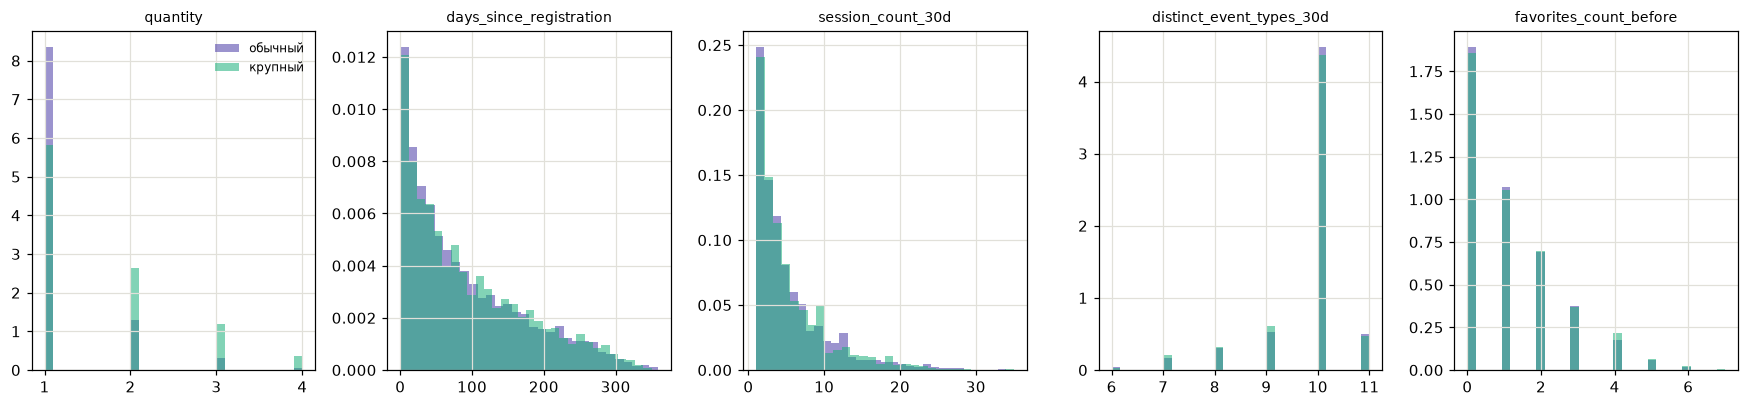

big_order,0,1
quantity,1.21,1.61
days_since_registration,90.23,93.38
session_count_30d,5.58,5.52
distinct_event_types_30d,9.79,9.75
favorites_count_before,1.10,1.15


In [3]:
features = ["quantity", "days_since_registration", "session_count_30d",
            "distinct_event_types_30d", "favorites_count_before"]
target = "big_order"

fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, col in zip(axes, features):
    for v, color, lab in [(0, C_ALT, "обычный"), (1, C_MAIN, "крупный")]:
        ax.hist(data.loc[data[target] == v, col], bins=30, alpha=0.55, color=color, label=lab, density=True)
    ax.set_title(col, fontsize=9)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig("hist_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

data.groupby(target)[features].mean().round(2).T

## 3. Выборки

Разбиение 80/20, стратифицировано по таргету.

In [4]:
X = data[features]
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)

train: (5932, 5)  test: (1484, 5)


## 4. KNN: выбор k

Перебираю нечётные `k` от 1 до 61 по кросс-валидации на train, метрика — F1. Масштабирование внутри пайплайна.

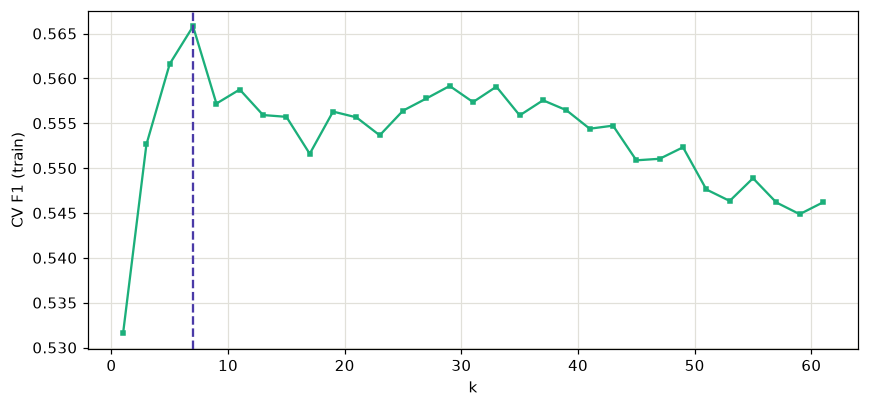

Лучшее k: 7  CV F1: 0.5658


In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe = Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier())])
grid = GridSearchCV(pipe, {"knn__n_neighbors": list(range(1, 62, 2))}, cv=skf, scoring="f1")
grid.fit(X_train, y_train)

k_scores = pd.DataFrame(grid.cv_results_)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(k_scores["param_knn__n_neighbors"].astype(int), k_scores["mean_test_score"], color=C_MAIN, marker="s", ms=3)
ax.axvline(grid.best_params_["knn__n_neighbors"], color=C_ALT, ls="--")
ax.set_xlabel("k")
ax.set_ylabel("CV F1 (train)")
plt.tight_layout()
plt.savefig("cv_k_f1.png", dpi=150, bbox_inches="tight")
plt.show()
print("Лучшее k:", grid.best_params_["knn__n_neighbors"], " CV F1:", round(grid.best_score_, 4))
model = grid.best_estimator_

## 5. Кривые precision-recall и ROC

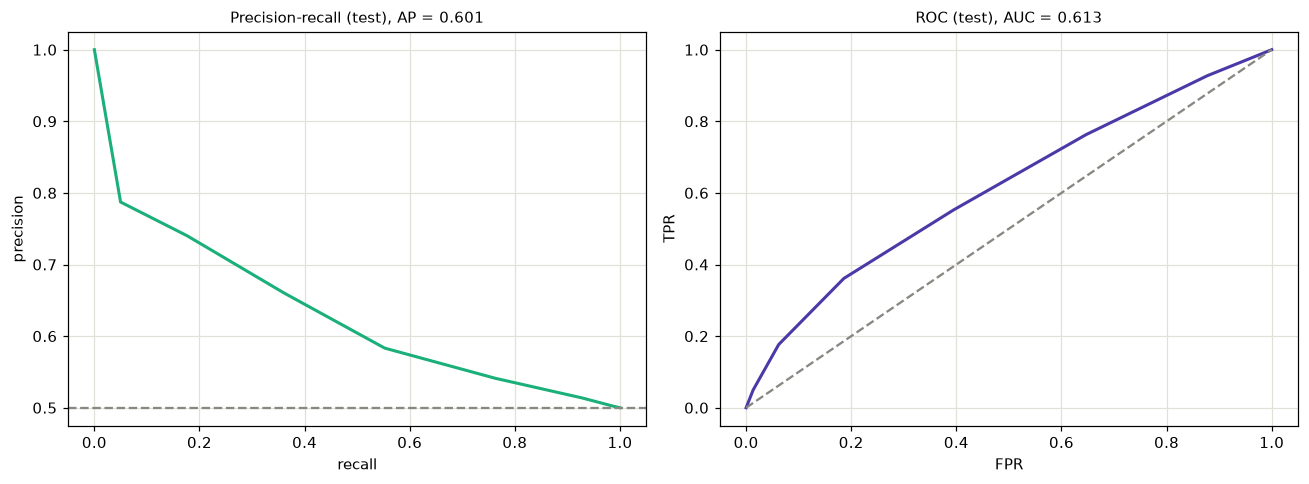

In [6]:
test_proba = model.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
prec, rec, _ = precision_recall_curve(y_test, test_proba)
axes[0].plot(rec, prec, color=C_MAIN, lw=2)
axes[0].axhline(y_test.mean(), color="#898781", ls="--")
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title(f"Precision-recall (test), AP = {average_precision_score(y_test, test_proba):.3f}", fontsize=10)

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=C_ALT, lw=2)
axes[1].plot([0, 1], [0, 1], color="#898781", ls="--")
axes[1].set_xlabel("FPR")
axes[1].set_ylabel("TPR")
axes[1].set_title(f"ROC (test), AUC = {roc_auc_score(y_test, test_proba):.3f}", fontsize=10)
plt.tight_layout()
plt.savefig("pr_roc.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Порог

Порог выбираю по индексу Юдена (TPR − FPR) на out-of-fold вероятностях train. Он симметричен по классам и не зависит от доли положительного класса, в отличие от F1.

In [7]:
oof = cross_val_predict(model, X_train, y_train, cv=skf, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof)
youden = tpr_o - fpr_o
threshold = float(thr_o[int(np.argmax(youden))])
print("Порог по Юдену:", round(threshold, 3), " J =", round(youden.max(), 3))

Порог по Юдену: 0.571  J = 0.154


## 7. Предсказания, матрица ошибок, метрики

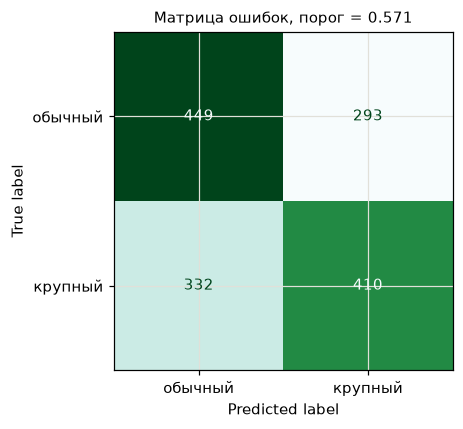

,Юден 0.571,порог 0.50
Accuracy,0.5788,0.5788
Precision,0.5832,0.5832
Recall,0.5526,0.5526
F1,0.5675,0.5675
ROC-AUC,0.6133,0.6133
PR-AUC (AP),0.6013,0.6013


In [8]:
y_pred = (test_proba >= threshold).astype(int)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["обычный", "крупный"]).plot(ax=ax, cmap="BuGn", colorbar=False)
ax.set_title(f"Матрица ошибок, порог = {threshold:.3f}", fontsize=10)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

def metrics(y_true, proba, pred):
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC (AP)": average_precision_score(y_true, proba),
    }

table = pd.DataFrame({
    f"Юден {threshold:.3f}": metrics(y_test, test_proba, y_pred),
    "порог 0.50": metrics(y_test, test_proba, (test_proba >= 0.5).astype(int)),
}).round(4)
table

## 8. Выводы

**Качество выше случайного.** На тесте ROC-AUC = 0.613 и PR-AUC = 0.601 при базовой доле 0.5. F1 = 0.568, accuracy = 0.579. Precision (0.583) и recall (0.553) близки, перекоса в одну сторону нет.

**Порог.** Порог по индексу Юдена = 0.571, и при порогах 0.5 и 0.571 метрики совпали. Причина в том, что k = 7, поэтому вероятности принимают дискретные значения 0, 1/7, 2/7, … При любом пороге между 3/7 (≈0.43) и 4/7 (≈0.57) предсказания одинаковы. Порог выбран формально, а не потому, что он что-то меняет.

**Какие признаки работают.** По средним в классах сильнее всего различается `quantity`: 1.21 у обычных заказов и 1.61 у крупных. По остальным признакам разница минимальна: дни с регистрации 90 против 93, сессии 5.6 против 5.5, типы событий 9.8 против 9.8, избранное 1.10 против 1.15. Поэтому модель по сути отличает заказы по числу единиц товара. Здесь это почти механически: `order_total` растёт с количеством. Без `quantity` качество, вероятно, сильно упало бы, но я этого не проверял.

**Вывод.** Поведенческие признаки (вовлечённость до заказа) практически не помогают предсказать крупный заказ. Это согласуется с ДЗ 3.1.2 и 3.1.3 для этой БД. В банковской версии KNN тоже почти не даёт сигнала (ROC-AUC 0.55), хотя там таргет другой.
